# Riduzione di dati astronomici: master di calibrazione e frame scientifici di AE UMa

**Autore:** Vincenzo Lippolis — Novembre 2026

## Scopo del notebook

Questo notebook implementa una pipeline completa di riduzione di dati CCD in formato FITS, propagando gli errori a ogni passaggio. È diviso in due parti:

- **Parte A – Creazione dei master di calibrazione** (bias, dark, flat) a partire dai frame grezzi, ciascuno con la propria **mappa d'errore** pixel per pixel.
- **Parte B – Riduzione in batch dei frame scientifici** (314 immagini di AE UMa): ogni frame viene calibrato con i master, convertito in elettroni e salvato con la mappa d'errore e una maschera di qualità dei pixel.
- **Parte C – Visualizzazione dei risultati**: grafici di un frame prima e dopo la riduzione e del rapporto segnale/rumore.
## Input e output

| | File |
|---|---|
| **Input Parte A** | frame grezzi `*bias.fit`, `dark*.fit`, `*flat.fit` nella cartella di calibrazione `calib`|
| **Output Parte A** | `master_bias.fits`, `master_dark.fits`, `master_flat.fits` e le mappe d'errore `*_err.fits` |
| **Input Parte B** | i master della Parte A e i frame `AE_UMa-*.fit*` nella cartella `sci` |
| **Output Parte B** | un file `reduced_*.fit` per ogni frame, nella cartella `red` |
| **Output Parte C** | grafici mostrati nel notebook e salvati come `grafico_C*.png` |

## 0. Librerie e impostazioni

Le librerie utilizzate sono:

- `os` e `glob`: costruzione dei percorsi e ricerca dei file tramite pattern (es. `*bias.fit`);
- `numpy`: operazioni su array, in particolare mediana e deviazione standard lungo un asse;
- `astropy.io.fits`: lettura e scrittura dei file FITS.

Nella stessa cella si definiscono le tre cartelle usate dal notebook, così che per cambiare dati basti modificare un solo punto.

In [1]:
import os
import glob
import numpy as np
from astropy.io import fits

# Cartella con i frame grezzi di calibrazione (bias, dark, flat)
calib_dir = "calib"
# Cartella con i frame scientifici grezzi (raw) di AE UMa
input_dir = "sci"
# Cartella in cui verranno salvati i frame ridotti (calibrati)
output_dir = "red"
os.makedirs(output_dir, exist_ok=True)

# Parte A – Creazione dei master di calibrazione

## 1. Funzioni di supporto

Per i tre master si ripetono le stesse operazioni, quindi conviene definire tre funzioni.

- **`load_and_stack`**: carica una lista di file FITS e li impila in un unico array 3D di forma (frame $\times$ $y$ $\times$ $x$).
- **`calculate_median_and_error`**: calcola la **mediana pixel per pixel** lungo l'asse dei frame e il suo errore:

$$\sigma_{\text{med}} = 1.253\,\frac{\sigma}{\sqrt{N}},$$

  dove $\sigma$ è la deviazione standard dei valori del pixel sugli $N$ frame. Il fattore $1.253 = \sqrt{\pi/2}$ è quello che si ottiene per l'errore asintotico della mediana nel caso di **rumore gaussiano**: l'errore è più grande di quello della media ($\sigma/\sqrt{N}$), ma la mediana ha il vantaggio di essere molto più **robusta agli outlier** (raggi cosmici, pixel difettosi).
- **`save_fits`**: salva un array in un file FITS, con un eventuale header. Viene chiamata separatamente per i dati e per le mappe d'errore.

In [2]:
def load_and_stack(file_list):
    """Carica i file FITS e li impila in un array 3D numpy."""
    data_list = []
    for fname in file_list:
        with fits.open(fname) as hdul:
            data_list.append(hdul[0].data.astype(np.float64))
    return np.array(data_list)

def calculate_median_and_error(stack):
    """
    Calcola la mediana lungo l'asse 0 e propaga l'errore sulla mediana.
    Errore_mediana = 1.253 * std / sqrt(N)
    """
    n_frames = stack.shape[0]
    median_img = np.median(stack, axis=0)
    std_img = np.std(stack, axis=0)

    # Formula di propagazione dell'errore per la mediana
    error_img = (1.253 * std_img) / np.sqrt(n_frames)
    return median_img, error_img

def save_fits(filename, data, header):
    """Salva un array in un file FITS (header opzionale)."""
    hdu = fits.PrimaryHDU(data, header=header)
    hdu.writeto(filename, overwrite=True)

## 2. Master Bias

Il **bias** è il livello di offset elettronico del sensore: lo si misura con frame a tempo di posa nullo (e senza luce). Il master bias è la mediana pixel per pixel dei frame di bias, con la relativa mappa d'errore. Vengono salvati `master_bias.fits` e `master_bias_err.fits`.

In [3]:
print("Processing Bias frames...")
bias_files = glob.glob(os.path.join(calib_dir, "*bias.fit"))
if not bias_files:
    raise FileNotFoundError("Nessun file Bias trovato.")

bias_stack = load_and_stack(bias_files)
master_bias, master_bias_err = calculate_median_and_error(bias_stack)

save_fits("master_bias.fits", master_bias, None)
save_fits("master_bias_err.fits", master_bias_err, None)
print(f"Creato Master Bias con mappa d'errore da {len(bias_files)} frame.")

Processing Bias frames...
Creato Master Bias con mappa d'errore da 9 frame.


## 3. Master Dark

I frame di **dark** (otturatore chiuso, tempo di posa $t_{\text{dark}}$) misurano il segnale termico del sensore, oltre al bias. Il procedimento è:

1. si sottrae il master bias da **ogni** frame di dark;
2. si calcola la mediana pixel per pixel dei dark così ottenuti, con il suo errore statistico $\sigma_{\text{dark,raw}}$.

L'errore del master bias si somma in quadratura all'errore statistico dei dark:

$$\sigma_{\text{dark}} = \sqrt{\sigma_{\text{dark,raw}}^2 + \sigma_{\text{bias}}^2}.$$

**Tempo di posa.** Poiché nella Parte B il dark va riscalato al tempo di posa di ciascun frame scientifico, il valore di `EXPTIME` dei dark deve essere conservato nell'header del master. Nel master viene copiata solo questa keyword, e non l'intero header di un dark originale.

In [4]:
print("\nProcessing Dark frames...")
dark_files = glob.glob(os.path.join(calib_dir, "dark*.fit"))
if not dark_files:
    raise FileNotFoundError("Nessun file Dark trovato.")

# Tempo di posa dei dark: deve essere unico e presente nell'header
dark_exptimes = {fits.getheader(f).get("EXPTIME") for f in dark_files}
dark_header = fits.Header()
dark_header["EXPTIME"] = (dark_exptimes.pop(), "Exposure time of the dark frames [s]")

dark_stack = load_and_stack(dark_files)

# Sottraiamo il Bias da ogni singolo frame
for i in range(len(dark_stack)):
    dark_stack[i] -= master_bias

# Calcoliamo la mediana dei Dark sottratti e il loro errore intrinseco
master_dark_raw, dark_err_raw = calculate_median_and_error(dark_stack)

# Propagazione dell'errore (quadratura): sigma_dark_tot = sqrt(sigma_dark_raw^2 + sigma_bias^2)
master_dark_err = np.sqrt(dark_err_raw**2 + master_bias_err**2)

save_fits("master_dark.fits", master_dark_raw, dark_header)
save_fits("master_dark_err.fits", master_dark_err, None)
print(f"Creato Master Dark ({dark_header['EXPTIME']} s) con mappa d'errore da {len(dark_files)} frame.")


Processing Dark frames...
Creato Master Dark (30.0 s) con mappa d'errore da 10 frame.


## 4. Master Flat

I frame di **flat** (illuminazione uniforme) misurano la risposta relativa dei pixel e le disomogeneità ottiche. Il procedimento è il seguente:

1. da ogni flat si sottraggono master bias e master dark;
2. si calcola la mediana dei flat sottratti, con il suo errore intrinseco $\sigma_{\text{flat,raw}}$;
3. si propaga l'errore della sottrazione sommando in quadratura i contributi:

$$\sigma_{\text{sub}} = \sqrt{\sigma_{\text{flat,raw}}^2 + \sigma_{\text{dark}}^2+\sigma_{\text{bias}}^2}.$$

4. si **normalizza** dividendo per la mediana globale dell'immagine, $K$, in modo che il flat abbia valore tipico $\approx 1$.

Quando dividiamo il Flat per la sua mediana e propaghiamo l’errore abbiamo che $\sigma_{\text{mediana}}$ è l'errore medio del frame diviso $\sqrt{N_{pixel}}$, che è numericamente quasi irrilevante. Possiamo approssimare il tutto dividendo semplicemente l'errore per la mediana.

In [5]:
print("\nProcessing Flat frames...")
flat_files = glob.glob(os.path.join(calib_dir, "*flat.fit"))
if not flat_files:
    raise FileNotFoundError("Nessun file Flat trovato.")

flat_stack = load_and_stack(flat_files)

# Sottraiamo Bias e Dark da ogni Flat
for i in range(len(flat_stack)):
    flat_stack[i] = flat_stack[i] - master_bias - master_dark_raw

# Mediana dei Flat e relativo errore intrinseco
master_flat_raw, flat_err_raw = calculate_median_and_error(flat_stack)

# Propagazione dell'errore della sottrazione: sigma_sub = sqrt(sigma_flat^2 + sigma_dark^2)
flat_err_sub = np.sqrt(flat_err_raw**2 + master_dark_err**2+master_bias_err**2)

# Normalizzazione
flat_median_value = np.median(master_flat_raw)
master_flat_normalized = master_flat_raw / flat_median_value
master_flat_err_normalized = flat_err_sub / flat_median_value

save_fits("master_flat.fits", master_flat_normalized, None)
save_fits("master_flat_err.fits", master_flat_err_normalized, None)
print(f"Creato Master Flat Normalizzato con mappa d'errore da {len(flat_files)} frame.")
print("\nCreazione dei master completata!")


Processing Flat frames...
Creato Master Flat Normalizzato con mappa d'errore da 9 frame.

Creazione dei master completata!


# Parte B – Riduzione in batch dei frame scientifici

## 5. Caricamento dei master

Si rileggono i master prodotti nella Parte A, insieme alle rispettive mappe d'errore. In questo modo la Parte B può essere eseguita anche da sola, a partire dai file `*.fits` già salvati.

Dall'header del master dark si legge il tempo di posa `EXPTIME`. Se la keyword manca il codice usa un valore di default di 30s.

In [6]:
# Master Bias
with fits.open("master_bias.fits") as h:
    master_bias = h[0].data.astype(np.float64)
with fits.open("master_bias_err.fits") as h:
    bias_err = h[0].data.astype(np.float64)

# Master Dark
with fits.open("master_dark.fits") as h:
    master_dark = h[0].data.astype(np.float64)
    dark_exptime = h[0].header.get("EXPTIME",30)  # Tempo di esposizione del Master Dark
with fits.open("master_dark_err.fits") as h:
    dark_err = h[0].data.astype(np.float64)

# Master Flat
with fits.open("master_flat.fits") as h:
    master_flat = h[0].data.astype(np.float64)
with fits.open("master_flat_err.fits") as h:
    flat_err = h[0].data.astype(np.float64)

print(f"Master caricati con successo! (EXPTIME master dark = {dark_exptime} s)")

Master caricati con successo! (EXPTIME master dark = 30.0 s)


## 6. La funzione di riduzione di un frame

`reduce_frame` applica la calibrazione a un singolo frame scientifico. Riceve il frame grezzo, il guadagno, il rumore di lettura (in $e^-$) e il tempo di posa $t_{\text{sci}}$, e usa i master caricati sopra. Successivamente esegue le seguenti operazioni:

**Passo 1 – Scalatura del dark.** Il segnale termico cresce con il tempo di posa, quindi il master dark e il suo errore vengono riscalati al tempo di posa del frame.

**Passo 2 – Calibrazione.** Si sottraggono bias e dark scalato, si converte in elettroni con il guadagno e si divide per il flat normalizzato.

**Passo 3 – Propagazione dell'errore.** Al numeratore contribuiscono, in quadratura, il rumore di Poisson dei conteggi, il rumore di lettura e gli errori dei master (convertiti in elettroni). La divisione per il flat si propaga con la regola dell'errore relativo. Per evitare divisioni per zero nel calcolo dell'errore relativo, un numeratore esattamente nullo viene sostituito da un valore molto piccolo (`1e-5`).

**Passo 4 – Pixel non validi.** I pixel in cui il risultato o l'errore non sono finiti (ad esempio per un flat nullo) vengono posti a `NaN` e segnalati nella maschera di *Data Quality*: $0$ = pixel valido, $1$ = pixel non valido.

In [7]:
def reduce_frame(raw_data, gain, rdnoise, sci_exptime):
    """
    Calibra un singolo frame scientifico. Restituisce:
    (immagine calibrata [e-], errore [e-], maschera DQ uint8).
    """
    # Passo 1: ridimensionamento del Dark in base al tempo di esposizione del frame
    dark_scale = sci_exptime / dark_exptime
    scaled_dark = master_dark * dark_scale
    scaled_dark_err = dark_err * dark_scale

    # Passo 2: riduzione matematica e conversione in elettroni
    numerator_adu = raw_data - master_bias - scaled_dark
    numerator_electrons = numerator_adu * gain

    # Divisione per il flat (con gestione degli errori di divisione per zero)
    with np.errstate(divide='ignore', invalid='ignore'):
        calibrated_science_electrons = numerator_electrons / master_flat

    # Passo 3: propagazione dell'errore (in elettroni)
    # Rumore di Poisson sui conteggi raw convertiti in elettroni
    shot_noise_electrons = np.sqrt(np.maximum(raw_data * gain, 0))

    # Combinazione quadratica degli errori al numeratore
    variance_numerator = (
        shot_noise_electrons**2 +
        rdnoise**2 +
        (gain * bias_err)**2 +
        (gain * scaled_dark_err)**2
    )
    sigma_numerator = np.sqrt(variance_numerator)

    # Protezione del numeratore da valori nulli per il calcolo dell'errore relativo
    safe_numerator = np.where(numerator_electrons == 0, 1e-5, numerator_electrons)

    # Incertezza relativa e calcolo dell'errore finale
    with np.errstate(divide='ignore', invalid='ignore'):
        relative_variance = (sigma_numerator / safe_numerator)**2 + (flat_err / master_flat)**2
        final_error_electrons = np.abs(calibrated_science_electrons) * np.sqrt(relative_variance)

    # Passo 4: maschera dei pixel non validi, marcati esplicitamente come NaN
    bad_pixel_mask = ~np.isfinite(calibrated_science_electrons) | ~np.isfinite(final_error_electrons)
    calibrated_science_electrons[bad_pixel_mask] = np.nan
    final_error_electrons[bad_pixel_mask] = np.nan

    # Data Quality: 0 = buono, 1 = invalido
    dq_array = bad_pixel_mask.astype(np.uint8)

    return calibrated_science_electrons, final_error_electrons, dq_array

## 7. Ciclo sui frame grezzi

Con `glob` si cercano tutti i file `AE_UMa-*.fit*` della cartella `sci`. I file vengono poi processati in ordine alfabetico: `sorted` rende l'ordine riproducibile ed `enumerate(..., 1)` affianca a ogni file un contatore che parte da 1, usato per mostrare l'avanzamento.

Per ciascun frame si leggono i dati e le keyword dell'header:

- `EGAIN`: guadagno in $e^-/\text{ADU}$;
- `EXPTIME`: tempo di posa del frame;
- `RDNOISE`: rumore di lettura in $e^-$, con valore di default di $9\,e^-$ se assente.

Ogni frame ridotto viene salvato nella cartella `red` con prefisso `reduced_`, come file FITS multi-estensione composto da tre HDU:

| HDU | Nome | Contenuto |
|---|---|---|
| 0 (primario) | `SCI` | immagine calibrata in elettroni, con l'header originale aggiornato (`BUNIT = ELECTRONS`) |
| 1 | `ERR` | mappa d'errore in elettroni |
| 2 | `DQ` | maschera di qualità dei pixel (0 = valido, 1 = non valido) |

In [8]:
# Cerchiamo tutti i file .fit o .fits che iniziano con AE_UMa-
search_pattern = os.path.join(input_dir, "AE_UMa-*.fit*")
raw_files = glob.glob(search_pattern)

if not raw_files:
    raise FileNotFoundError(f"Nessun file raw trovato in '{input_dir}' con il pattern 'AE_UMa-*.fit*'.")

print(f"Trovati {len(raw_files)} file grezzi da elaborare.")

for i, filepath in enumerate(sorted(raw_files), 1):
    filename = os.path.basename(filepath)
    print(f"[{i}/{len(raw_files)}] Riduzione in corso: {filename}...")

    # Lettura del singolo frame raw e dei metadati
    with fits.open(filepath) as h_sci:
        sci_header = h_sci[0].header
        raw_data = h_sci[0].data.astype(np.float64)

        gain = sci_header["EGAIN"]
        rdnoise = sci_header.get("RDNOISE", 9.0)     # Default stimato di 9.0 e-
        sci_exptime = sci_header["EXPTIME"]          # Tempo di esposizione del frame

    # Riduzione, errore e maschera
    calibrated, error, dq = reduce_frame(raw_data, gain, rdnoise, sci_exptime)

    # Creazione del file Multi-Extension FITS (MEF)
    primary_hdu = fits.PrimaryHDU(data=calibrated.astype(np.float32), header=sci_header)
    primary_hdu.header["OBJECT"] = "AE UMa"
    primary_hdu.header["BUNIT"] = "ELECTRONS"
    primary_hdu.header["EXTNAME"] = "SCI"
    primary_hdu.header["COMMENT"] = "Calibrato con pipeline di riduzione batch."

    err_hdu = fits.ImageHDU(data=error.astype(np.float32), name="ERR")
    err_hdu.header["BUNIT"] = "ELECTRONS"

    dq_hdu = fits.ImageHDU(data=dq, name="DQ")
    dq_hdu.header["COMMENT"] = "0 = pixel valido, 1 = invalido (es. flat nullo)"

    fits.HDUList([primary_hdu, err_hdu, dq_hdu]).writeto(
        os.path.join(output_dir, f"reduced_{filename}"), overwrite=True)

print("\nProcesso di calibrazione batch completato con successo!")
print(f"Tutti i file ridotti sono salvati nella cartella '{output_dir}'.")

Trovati 314 file grezzi da elaborare.
[1/314] Riduzione in corso: AE_UMa-0001.fit...
[2/314] Riduzione in corso: AE_UMa-0002.fit...
[3/314] Riduzione in corso: AE_UMa-0003.fit...
[4/314] Riduzione in corso: AE_UMa-0004.fit...
[5/314] Riduzione in corso: AE_UMa-0005.fit...
[6/314] Riduzione in corso: AE_UMa-0006.fit...
[7/314] Riduzione in corso: AE_UMa-0007.fit...
[8/314] Riduzione in corso: AE_UMa-0008.fit...
[9/314] Riduzione in corso: AE_UMa-0009.fit...
[10/314] Riduzione in corso: AE_UMa-0010.fit...
[11/314] Riduzione in corso: AE_UMa-0011.fit...
[12/314] Riduzione in corso: AE_UMa-0012.fit...
[13/314] Riduzione in corso: AE_UMa-0013.fit...
[14/314] Riduzione in corso: AE_UMa-0014.fit...
[15/314] Riduzione in corso: AE_UMa-0015.fit...
[16/314] Riduzione in corso: AE_UMa-0016.fit...
[17/314] Riduzione in corso: AE_UMa-0017.fit...
[18/314] Riduzione in corso: AE_UMa-0018.fit...
[19/314] Riduzione in corso: AE_UMa-0019.fit...
[20/314] Riduzione in corso: AE_UMa-0020.fit...
[21/314] Ri

# Parte C – Visualizzazione dei risultati

Questa parte mostra alcuni risultati dell'analisi. Per prima cosa il codice affianca lo stesso frame **grezzo** (in ADU) e **ridotto** (in $e^-$). Nel frame grezzo il fondo è dominato dal livello di bias e dalle disomogeneità del sensore e dell'ottica; dopo la calibrazione il fondo cielo dovrebbe risultare uniforme e le stelle ben distinguibili. Le due immagini sono visualizzate entrambe in scala di verdi, ma con **intervalli di valori diversi** (le colorbar mostrano i limiti di ciascuna), perché le unità sono diverse (ADU contro elettroni); per ciascuna i limiti sono scelti con l'algoritmo *ZScale*, che si basa sulla mediana ignorando le stelle più brillanti, così da far emergere il fondo cielo. I pixel non validi (`NaN`) compaiono in **rosso**; se non si vede nessun pixel rosso, la maschera è vuota. 

Successivamente il codice divide il frame ridotto per la sua mappa d'errore, pixel per pixel, e si ottiene il rapporto segnale/rumore. A sinistra la mappa di S/N, a destra l'istogramma dei suoi valori (asse verticale logaritmico). Viene stampato anche il valore mediano, che rappresenta il rapporto S/N tipico del fondo cielo. Sul **fondo cielo** la mappa è piuttosto uniforme, perché il rumore è dominato dal rumore di Poisson del cielo e dal rumore di lettura; le **stelle** emergono come picchi, tanto più alti quanto più la sorgente è brillante: l'S/N indica dove la misura è affidabile, ad esempio per scegliere le stelle di confronto in fotometria; i pixel non validi (`NaN`) sono esclusi dall'istogramma.

S/N mediano del frame = 11.0


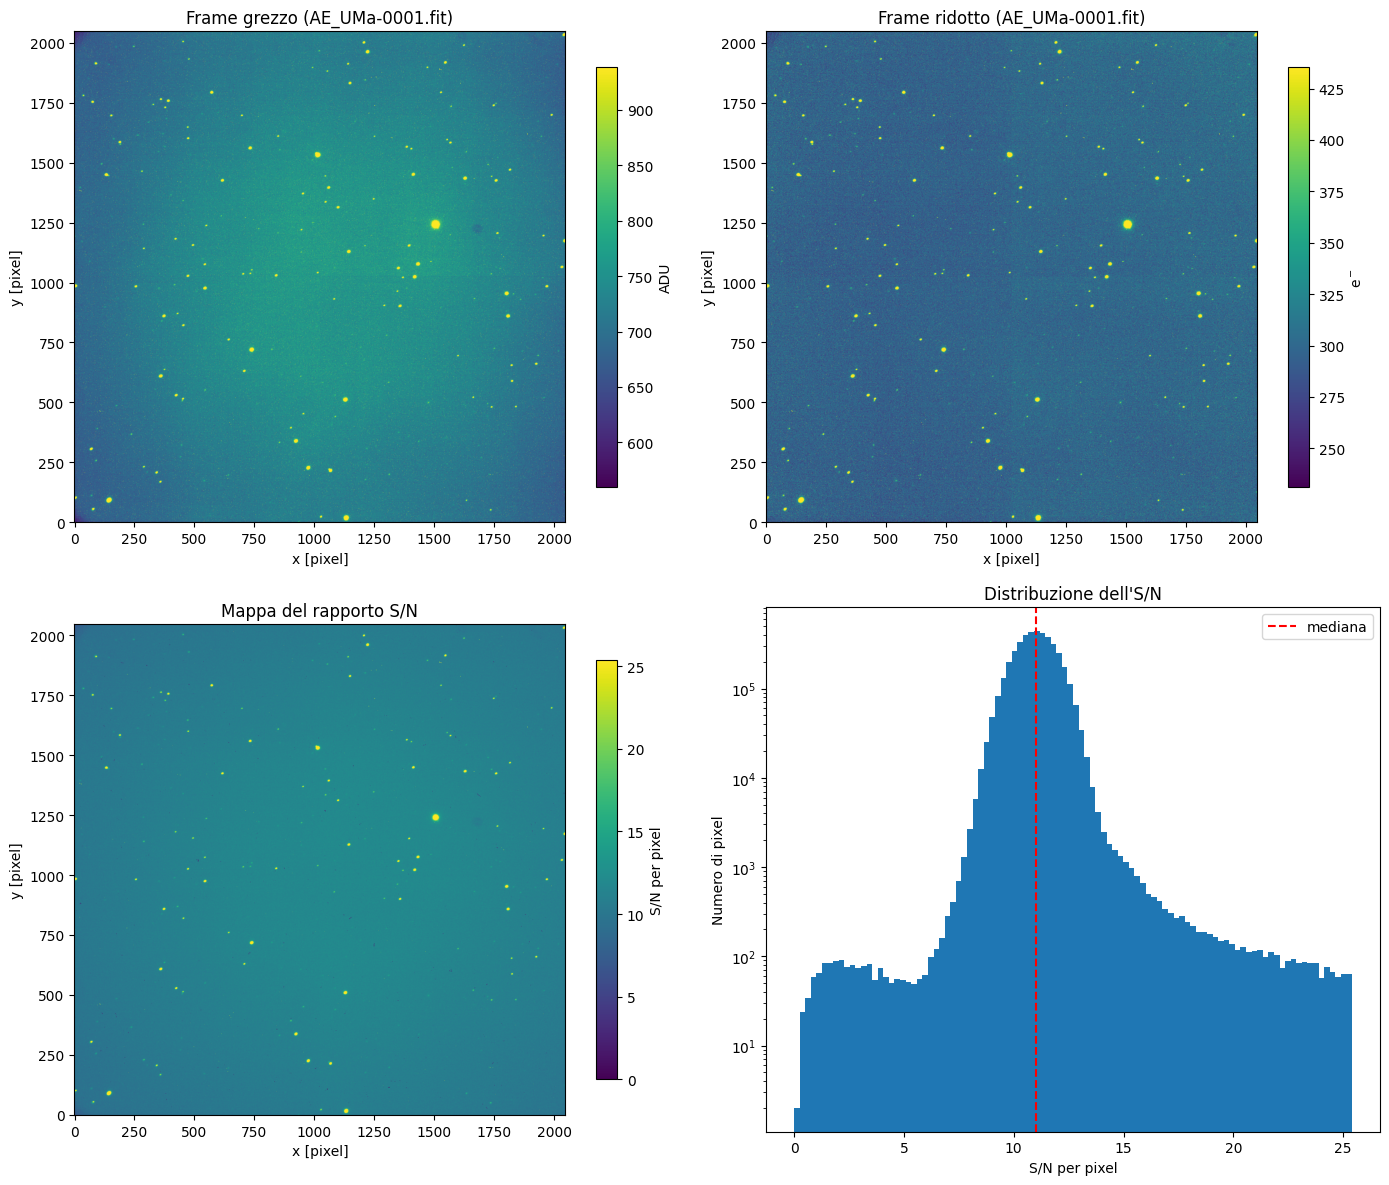

In [9]:
import matplotlib.pyplot as plt
from astropy.visualization import ImageNormalize, ZScaleInterval

frame_name = "AE_UMa-0001.fit"   # frame da mostrare

with fits.open(os.path.join(input_dir, frame_name)) as h:
    raw = h[0].data.astype(np.float64)
with fits.open(os.path.join(output_dir, "reduced_" + frame_name)) as h:
    sci = h[0].data.astype(np.float64)
    err = h["ERR"].data.astype(np.float64)

# Rapporto segnale/rumore pixel per pixel
with np.errstate(divide="ignore", invalid="ignore"):
    snr = sci / err
good = np.isfinite(snr)
vmax = np.percentile(snr[good], 99.9)
print(f"S/N mediano del frame = {np.median(snr[good]):.1f}")

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("red")   # pixel non validi (NaN) in rosso

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Riga superiore: frame grezzo e frame ridotto
for ax, img, title, unit in [(axes[0, 0], raw, "Frame grezzo", "ADU"),
                             (axes[0, 1], sci, "Frame ridotto", r"e$^-$")]:
    norm = ImageNormalize(img, interval=ZScaleInterval())
    im = ax.imshow(img, origin="lower", cmap=cmap, norm=norm)
    ax.set_title(f"{title} ({frame_name})")
    ax.set_xlabel("x [pixel]")
    ax.set_ylabel("y [pixel]")
    fig.colorbar(im, ax=ax, label=unit, shrink=0.8)

# Riga inferiore: mappa S/N e istogramma
im = axes[1, 0].imshow(snr, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
axes[1, 0].set_title("Mappa del rapporto S/N")
axes[1, 0].set_xlabel("x [pixel]")
axes[1, 0].set_ylabel("y [pixel]")
fig.colorbar(im, ax=axes[1, 0], label="S/N per pixel", shrink=0.8)

axes[1, 1].hist(snr[good].ravel(), bins=100, range=(0, vmax), log=True)
axes[1, 1].axvline(np.median(snr[good]), color="r", ls="--", label="mediana")
axes[1, 1].set_xlabel("S/N per pixel")
axes[1, 1].set_ylabel("Numero di pixel")
axes[1, 1].set_title("Distribuzione dell'S/N")
axes[1, 1].legend()

plt.tight_layout()
plt.show()